In [4]:
# Moduli di scikit-learn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV, ParameterGrid, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

import ml_utilities
import ml_visualization

In [5]:
# Caricamento del dataset
feature_count = 16
dataset_path = 'DBs/PenDigits/pendigits_tr.txt'  # Impostare il percorso corretto

dataset_patterns, dataset_labels = ml_utilities.load_labeled_dataset_from_txt(dataset_path, feature_count)

# Test
Si addestri il classificatore desiderato utilizzando gli iperparametri trovati nell'esercizio precedente. Il codice contenuto nella cella seguente userà tale classificatore per predire la classe dei pattern del dataset di test. Le classi predette verranno salvate su un file di testo che dovrà essere caricato sul sito della competizione per misurarne l'accuratezza.

Il file `pendigits_te.txt` contiene 5000 pattern 16-dimensionali non etichettati.

Sul sito della competizione dovrà essere caricato uno zip contenente sia il file di testo `Es3Predictions.txt` che una cartella `Codice` contenente il codice (notebook e script) da utilizzare per replicare il risultato.

Il file `.zip` da caricare sul sito della competizione dovrà avere necessariemente la seguente struttura:
```
<nomefile>.zip
├── Codice
│   └── <tutto il codice usato per training e test del classificatore>
└── Es3Predictions.txt
```

NB: all'interno dello zip il file `Es3Predictions.txt` non deve essere contenuto in una cartella.

**Regole per la competition:**
* Si possono usare solo **classificatori K-Nearest Neighbors e Support Vector Machines**.
* **Non sono ammessi ensemble di modelli.**
* Si possono variare a piacimento gli iperparametri dei classificatori.
* **Non è possibile utilizzare altre feature in aggiunta o in sostituzione a quelle esistenti.**
* **Non è possibile espandere il dataset** aggiungendo manualmente pattern al di fuori di quelli forniti.
* **Non è possibile utilizzare tecniche di data augmentation** per aumentare artificialmente il numero di pattern del dataset (es. rotazioni, traslazioni, scalature, eccetera).
* **È invece possibile** fare rescaling/standardization delle feature. In tal caso, ci si assicuri di non fittare lo scaling sul test set: si devono apprendere i valori per il rescaling solo sul training set tramite `.fit_transform()` per gli scaler da Scikit-learn, e sul test set si chiama solo `.transform()` per applicare sul test set la trasformazione appresa dal training set.
* **È possibile** usare tecnice di riduzione di dimensionalità come **PCA** sul dataset.
* La soglia per ricevere 2 punti in classifica è avere una **accuracy sul test set maggiore o uguale a 85%.**

In [ ]:
# Esercizio 4: valutazione su test set
result_path = 'Es3Predictions.txt'

# Caricamento del dataset
feature_count = 16
test_path = 'DBs/PenDigits/pendigits_te.txt'

test_x = ml_utilities.load_unlabeled_dataset_from_txt(test_path, feature_count)

# Creazione della griglia di iperparametri
param_grid = [
    {
        'knn__n_neighbors':[3,4,5,6,7,8,9,10],
        'knn__weights':['uniform', 'distance'],
 #       'knn__algorithm':['auto', 'ball_tree', 'kd_tree', 'brute'],
        'knn__metric':['euclidean', 'chebyshev','cosine'],
    }
]

pipe = Pipeline(steps=[
    ('standardscaler', StandardScaler()),
    ('pca', PCA(n_components=8)),
    ('knn', KNeighborsClassifier())
])

# Numero di fold per la Cross-validation
n_folds = 5

# Creazione di un oggetto di tipo GridSearchCV
grid_search_cv = GridSearchCV(pipe, param_grid, cv=n_folds, n_jobs=-1)

# Esecuzione della ricerca degli iperparametri 
grid_search_cv.fit(dataset_patterns, dataset_labels)

# Stampa risultati
print('Combinazioni di parametri:\n', grid_search_cv.cv_results_['params'])
print('Accuratezza media per combinazione:\n', grid_search_cv.cv_results_['mean_test_score'])
print('Combinazione migliore:\n', grid_search_cv.best_params_)
print('Accuratezza media della combinazione migliore: %.3f' % grid_search_cv.best_score_)

# Costruisce un classificatore con i parametri trovati
clf = grid_search_cv.best_estimator_
print('Classificatore con parametri ottimali:\n', clf, '\n')

# Cross validation
cv_score = cross_val_score(clf, dataset_patterns, dataset_labels, cv=n_folds)
print('Accuracy di cross validation: ', cv_score)
print('Accuracy media di cross validation: ', cv_score.mean())

# Addestramento su tutto il dataset
clf = grid_search_cv.best_estimator_
clf.fit(dataset_patterns, dataset_labels)
print('Accuracy classificatore addestrato su tutto il training set:', clf.score(dataset_patterns, dataset_labels))

# Calcolo delle prediction
predictions = clf.predict(test_x)

# Salvataggio delle prediction
with open(result_path, "w") as f:
    for prediction in predictions:
        f.write(str(int(prediction)) + '\n')
print('Salvataggio delle prediction riuscito')

In [ ]:
#for i in range(test_x.shape[0]):
i=2898
x = test_x[i][::2]
y = test_x[i][1::2]

plt.figure(figsize=(8, 6))

#plt.scatter per visualizzare i singoli punti
plt.scatter(x, y, color='blue', s=50, label='Punti (x, y)')

# (Opzionale) plt.plot per unire i punti in ordine con una linea tratteggiata
plt.plot(x, y, linestyle='--', color='gray', alpha=0.6, label='Linee di collegamento')

# Personalizzazione del grafico
plt.xlabel('Valori X')
plt.ylabel('Valori Y')
plt.title('Grafico delle 8 coppie di coordinate')
plt.grid(True)
plt.legend()

# Mostra il grafico
plt.show()

In [10]:
np.logspace(-4,0,10)

array([1.00000000e-04, 2.78255940e-04, 7.74263683e-04, 2.15443469e-03,
       5.99484250e-03, 1.66810054e-02, 4.64158883e-02, 1.29154967e-01,
       3.59381366e-01, 1.00000000e+00])

/home/gioele/Documents/Unibo/MachineLearning/ML-Lab/.venv/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Combinazioni di parametri:
 [{'pca__n_components': 13, 'pca__whiten': True, 'standardscaler__with_std': True, 'svc__C': np.float64(0.5), 'svc__decision_function_shape': 'ovo', 'svc__gamma': np.float64(0.0001), 'svc__kernel': 'rbf'}, {'pca__n_components': 13, 'pca__whiten': True, 'standardscaler__with_std': True, 'svc__C': np.float64(0.5), 'svc__decision_function_shape': 'ovo', 'svc__gamma': np.float64(0.00019306977288832496), 'svc__kernel': 'rbf'}, {'pca__n_components': 13, 'pca__whiten': True, 'standardscaler__with_std': True, 'svc__C': np.float64(0.5), 'svc__decision_function_shape': 'ovo', 'svc__gamma': np.float64(0.0003727593720314938), 'svc__kernel': 'rbf'}, {'pca__n_components': 13, 'pca__whiten': True, 'standardscaler__with_std': True, 'svc__C': np.float64(0.5), 'svc__decision_function_shape': 'ovo', 'svc__gamma': np.float64(0.0007196856730011522), 'svc__kernel': 'rbf'}, {'pca__n_components': 13, 'pca__whiten': True, 'standardscaler__with_std': True, 'svc__C': np.float64(0.5), '

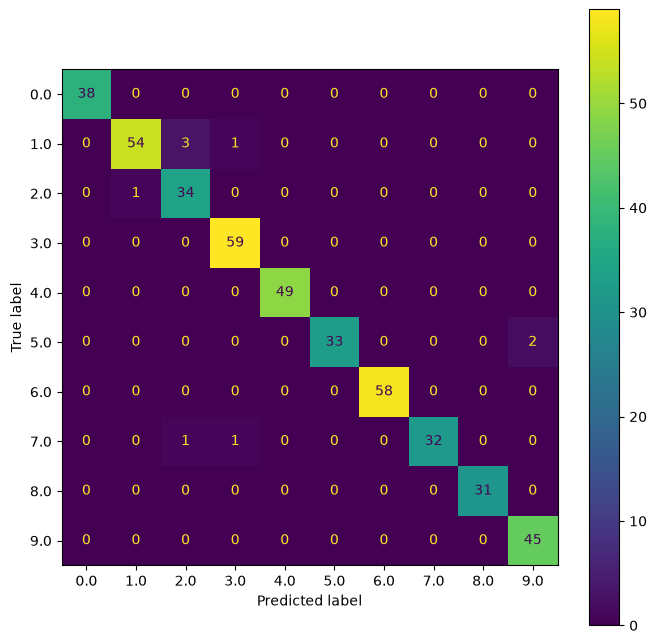

In [ ]:
# Esercizio 4: valutazione su test set
result_path = 'Es3Predictions.txt'

# Caricamento del dataset
feature_count = 16
test_path = 'DBs/PenDigits/pendigits_te.txt'

test_x = ml_utilities.load_unlabeled_dataset_from_txt(test_path, feature_count)

# Creazione della griglia di iperparametri
'''
param_grid = [
    {
        'svc__kernel': ['rbf'],
        'svc__C': np.linspace(1.0, 1.5, 11),
        'svc__gamma': np.linspace(0.1, 0.15, 11),
        'svc__decision_function_shape': ['ovo']
    }
]
'''


#{'pca__n_components': 14, 'pca__whiten': False, 'standardscaler__with_std': False, 'svc__C': 0.774263682681127, 'svc__decision_function_shape': 'ovo', 'svc__gamma': 0.0001, 'svc__kernel': 'rbf'}

param_grid = [
    {
        'standardscaler__with_std':[True,False],
        'svc__C': np.linspace(0.5, 2.5, 15),
        'svc__kernel': ['rbf'],
        'svc__gamma':np.logspace(-4,0,15),
        'svc__decision_function_shape': ['ovo'],
        'pca__n_components':[13],
        'pca__whiten':[True,False]
    }
]

# C: 2
# gamma: 0.15

pipe = Pipeline(steps=[
    ('standardscaler', StandardScaler()),
    ('pca', PCA()),
    ('svc', SVC())
])

# Numero di fold per la Cross-validation
n_folds = 4

# Creazione di un oggetto di tipo GridSearchCV
grid_search_cv = GridSearchCV(
    pipe,
    param_grid,
    cv=n_folds,
    n_jobs=-1)

# Esecuzione della ricerca degli iperparametri 
grid_search_cv.fit(dataset_patterns, dataset_labels)

# Stampa risultati
print('Combinazioni di parametri:\n', grid_search_cv.cv_results_['params'])
print('Accuratezza media per combinazione:\n', grid_search_cv.cv_results_['mean_test_score'])
print('Combinazione migliore:\n', grid_search_cv.best_params_)
print('Accuratezza media della combinazione migliore: %.3f' % grid_search_cv.best_score_)

# Costruisce un classificatore con i parametri trovati
clf = grid_search_cv.best_estimator_
print('Classificatore con parametri ottimali:\n', clf, '\n')

# Cross validation
cv_score = cross_val_score(clf, dataset_patterns, dataset_labels, cv=n_folds)
print('Accuracy di cross validation: ', cv_score)
print('Accuracy media di cross validation: ', cv_score.mean())

# Addestramento su tutto il dataset
clf = grid_search_cv.best_estimator_
clf.fit(dataset_patterns, dataset_labels)
print('Accuracy classificatore addestrato su tutto il training set:', clf.score(dataset_patterns, dataset_labels))
_ = ConfusionMatrixDisplay.from_estimator(clf, dataset_patterns, dataset_labels)

# Calcolo delle prediction
predictions = clf.predict(test_x)

# Salvataggio delle prediction
with open(result_path, "w") as f:
    for prediction in predictions:
        f.write(str(int(prediction)) + '\n')
print('Salvataggio delle prediction riuscito')